# Experiment 6 Sentiment Analysis using LSTM

## PART A: Dataset Preparation and Text Preprocessing

In [2]:
print("24BAD004")
print("K ADHITHYA")

24BAD004
K ADHITHYA


In [ ]:
# K ADHITHYA - 24BAD004
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

nltk.download('stopwords')
nltk.download('punkt')
nltk.download('punkt_tab')
print("K ADHITHYA - 24BAD004")

# load the dataset
df = pd.read_csv("https://raw.githubusercontent.com/Ankit152/IMDB-sentiment-analysis/master/IMDB-Dataset.csv")
df.head()

I0000 00:00:1790732320.753491      86 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1790732321.176802      86 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1790732323.220074      86 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


K ADHITHYA - 24BAD004


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


Checking the dataset

Number of samples: 50000
sentiment
positive    25000
negative    25000
Name: count, dtype: int64

Positive review:
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Tru

Negative review:
Basically there's a family where a little boy (Jake) thinks there's a zombie in his closet & his parents are fighting all the time.<br /><br />This movie is slower than a soap opera... and suddenly, Jake decides to become Rambo and kill the zombie.<br /><br />OK, first of all when you're going to ma


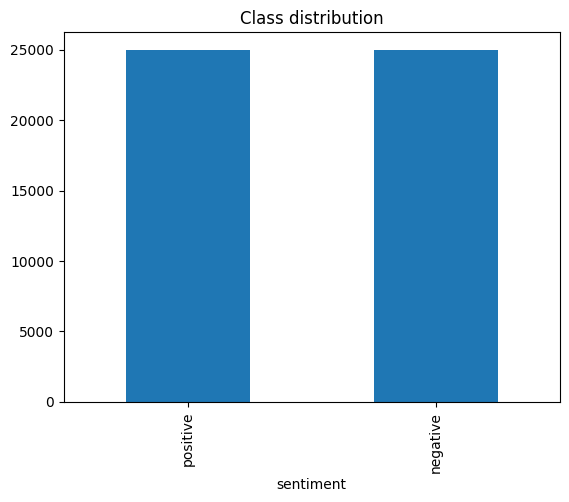

In [2]:
print("Number of samples:", len(df))
print(df['sentiment'].value_counts())

# sample reviews
print("\nPositive review:")
print(df[df['sentiment'] == 'positive']['review'].iloc[0][:300])
print("\nNegative review:")
print(df[df['sentiment'] == 'negative']['review'].iloc[0][:300])

df['sentiment'].value_counts().plot(kind='bar')
plt.title("Class distribution")
plt.show()

Text preprocessing

In [3]:
# not, no and nor are kept because they change the meaning of a review
stop_words = set(stopwords.words('english')) - {'no', 'not', 'nor'}

def clean_text(text):
    text = text.lower()                       # lowercase
    text = re.sub(r'<.*?>', ' ', text)        # remove html tags
    text = re.sub(r'[^a-z\s]', ' ', text)     # remove punctuation and special characters
    words = word_tokenize(text)               # tokenize
    words = [w for w in words if w not in stop_words]   # remove stop words
    return ' '.join(words)

df['clean'] = df['review'].apply(clean_text)

print(df['review'][0][:150])
print(df['clean'][0][:150])

One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with
one reviewers mentioned watching oz episode hooked right exactly happened first thing struck oz brutality unflinching scenes violence set right word g


Label encoding and train / validation / test split

In [4]:
# negative = 0, positive = 1
le = LabelEncoder()
y = le.fit_transform(df['sentiment'])
print(le.classes_)

# 70% train, 15% validation, 15% test
X_train_text, X_temp, y_train, y_temp = train_test_split(df['clean'], y, test_size=0.3, random_state=42, stratify=y)
X_val_text, X_test_text, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

print(len(X_train_text), len(X_val_text), len(X_test_text))

['negative' 'positive']
35000 7500 7500


Tokenizer, vocabulary and padding

In [5]:
vocab_size = 10000
max_len = 200

# vocabulary is built only from the training reviews
tokenizer = Tokenizer(num_words=vocab_size, oov_token='<OOV>')
tokenizer.fit_on_texts(X_train_text)
print("Words in vocabulary:", len(tokenizer.word_index))

# text -> numbers
X_train_seq = tokenizer.texts_to_sequences(X_train_text)
X_val_seq = tokenizer.texts_to_sequences(X_val_text)
X_test_seq = tokenizer.texts_to_sequences(X_test_text)
print(X_train_seq[0][:15])

# padding so all reviews have same length
X_train = pad_sequences(X_train_seq, maxlen=max_len, padding='pre', truncating='post')
X_val = pad_sequences(X_val_seq, maxlen=max_len, padding='pre', truncating='post')
X_test = pad_sequences(X_test_seq, maxlen=max_len, padding='pre', truncating='post')

print(X_train.shape, X_val.shape, X_test.shape)
print(X_train[0][-15:])

Words in vocabulary: 85316


[82, 14, 181, 563, 677, 4, 62, 2513, 1879, 609, 4421, 1, 129, 59, 2639]


(35000, 200) (7500, 200) (7500, 200)
[ 373 4529  190  177 8883  187   18  224 2272 4463  444  434  138 3064
    1]


## PART B: Embedding Generation

In [6]:
# K ADHITHYA - 24BAD004
import tensorflow as tf
from tensorflow.keras.layers import Embedding

print("K ADHITHYA - 24BAD004")

embed_dim = 64
print("Vocabulary size:", vocab_size)
print("Embedding dimension:", embed_dim)

embedding_layer = Embedding(input_dim=vocab_size, output_dim=embed_dim)

# convert first 5 reviews into dense vectors
sample = X_train[:5]
embedded = embedding_layer(sample)
print("Input shape:", sample.shape)
print("Embedding output shape:", embedded.shape)

K ADHITHYA - 24BAD004
Vocabulary size: 10000
Embedding dimension: 64
Input shape: (5, 200)
Embedding output shape: (5, 200, 64)


In [7]:
# how words are represented
word_index = tokenizer.word_index
weights = embedding_layer.get_weights()[0]
print("Weight matrix shape:", weights.shape)

for w in ['good', 'bad', 'movie']:
    print(w, "-> index", word_index[w], "->", np.round(weights[word_index[w]][:6], 3))

Weight matrix shape: (10000, 64)
good -> index 7 -> [-0.016 -0.021 -0.005  0.012  0.037 -0.049]
bad -> index 17 -> [-0.046  0.03  -0.032  0.008 -0.027 -0.037]
movie -> index 2 -> [ 0.019  0.013 -0.04  -0.004  0.048  0.037]


## PART C: Implementing the LSTM Model

In [8]:
# K ADHITHYA - 24BAD004
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Dropout

print("K ADHITHYA - 24BAD004")
tf.random.set_seed(42)

inputs = Input(shape=(max_len,))
x = Embedding(input_dim=vocab_size, output_dim=embed_dim, mask_zero=True)(inputs)
x = LSTM(64)(x)
x = Dropout(0.3)(x)
outputs = Dense(1, activation='sigmoid')(x)

model = Model(inputs, outputs)

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model.summary()

K ADHITHYA - 24BAD004


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 200)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, 200, 64)   │    640,000 │ input_layer[0][0] │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 200)       │          0 │ input_layer[0][0] │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 64)        │     33,024 │ embedding_1[0][0… │
│                     │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 64)        │          0 │ lstm[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 1)         │         65 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 673,089 (2.57 MB)

 Trainable params: 673,089 (2.57 MB)

 Non-trainable params: 0 (0.00 B)

## PART D: Model Training and Sentiment Prediction

In [10]:
# K ADHITHYA - 24BAD004
print("K ADHITHYA - 24BAD004")

history = model.fit(X_train, y_train, epochs=5, batch_size=64,
                    validation_data=(X_val, y_val), verbose=2)

K ADHITHYA - 24BAD004
Epoch 1/5


E0000 00:00:1790732360.111101      86 util.cc:131] oneDNN supports DT_BOOL only on platforms with AVX-512. Falling back to the default Eigen-based implementation if present.


547/547 - 80s - 145ms/step - accuracy: 0.8340 - loss: 0.3723 - val_accuracy: 0.8728 - val_loss: 0.3094


Epoch 2/5


547/547 - 83s - 151ms/step - accuracy: 0.9100 - loss: 0.2377 - val_accuracy: 0.8720 - val_loss: 0.3219


...

547/547 - 81s - 148ms/step - accuracy: 0.9319 - loss: 0.1852 - val_accuracy: 0.8645 - val_loss: 0.3391


Epoch 4/5


547/547 - 77s - 140ms/step - accuracy: 0.9383 - loss: 0.1678 - val_accuracy: 0.8561 - val_loss: 0.4066


Epoch 5/5


547/547 - 81s - 148ms/step - accuracy: 0.9561 - loss: 0.1286 - val_accuracy: 0.8616 - val_loss: 0.4667


In [11]:
print("K ADHITHYA - 24BAD004")
print("Epoch  Train Acc  Val Acc  Train Loss  Val Loss")
for i in range(5):
    print(i+1, "     ",
          round(history.history['accuracy'][i], 4), "   ",
          round(history.history['val_accuracy'][i], 4), "  ",
          round(history.history['loss'][i], 4), "    ",
          round(history.history['val_loss'][i], 4))

K ADHITHYA - 24BAD004
Epoch  Train Acc  Val Acc  Train Loss  Val Loss
1       0.834     0.8728    0.3723      0.3094
2       0.91     0.872    0.2377      0.3219
3       0.9319     0.8645    0.1852      0.3391
4       0.9383     0.8561    0.1678      0.4066
5       0.9561     0.8616    0.1286      0.4667


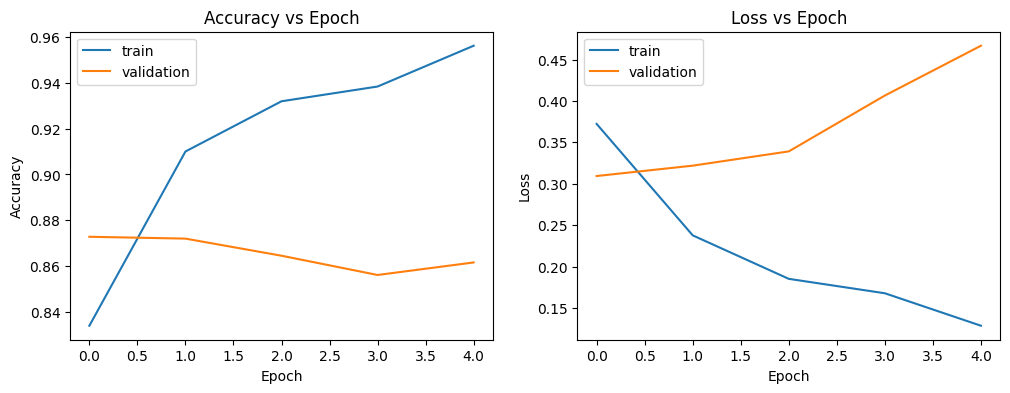

In [12]:
# accuracy and loss graphs
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='validation')
plt.title('Accuracy vs Epoch')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='validation')
plt.title('Loss vs Epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.show()

Evaluation on test data

In [13]:
print("K ADHITHYA - 24BAD004")
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print("Test loss:", round(test_loss, 4))
print("Test accuracy:", round(test_acc, 4))

K ADHITHYA - 24BAD004


Test loss: 0.4386
Test accuracy: 0.8691


Predicting sample reviews

In [14]:
y_prob = model.predict(X_test, verbose=0).ravel()
y_pred = (y_prob > 0.5).astype(int)
names = ['negative', 'positive']

# first 8 test reviews, actual vs predicted
for i in range(8):
    print("Review:", X_test_text.iloc[i][:70], "...")
    print("Actual:", names[y_test[i]], "| Predicted:", names[y_pred[i]], "| Prob:", round(float(y_prob[i]), 3))
    print()

Review: parents used rent lot horror movies child loved watching even bad made ...
Actual: negative | Predicted: negative | Prob: 0.003

Review: got chance see movie early screening brea crazy ever since film based  ...
Actual: positive | Predicted: positive | Prob: 0.998

Review: well previews looked funny usually go movies opening night especially  ...
Actual: negative | Predicted: negative | Prob: 0.0

Review: true lover film must advise avoid appalling effort god knows funding a ...
Actual: negative | Predicted: negative | Prob: 0.001

Review: first saw movie teenager came theaters way back seeing nearly years la ...
Actual: positive | Predicted: positive | Prob: 0.97

Review: one joan crawford best talkies first gable crawford pairing made evide ...
Actual: positive | Predicted: positive | Prob: 0.998

Review: huge charlton heston fan without doubt one greatest actors time thinki ...
Actual: negative | Predicted: negative | Prob: 0.001

Review: thunderbirds immensely popular sixti

In [15]:
# trying my own reviews
def predict_review(text):
    seq = tokenizer.texts_to_sequences([clean_text(text)])
    seq = pad_sequences(seq, maxlen=max_len, padding='pre', truncating='post')
    p = float(model.predict(seq, verbose=0)[0][0])
    return names[int(p > 0.5)], round(p, 3)

print(predict_review("This movie was fantastic, I loved the acting and the story!"))
print(predict_review("Terrible film. Boring plot and very bad acting, a waste of time."))

('positive', 0.803)


('negative', 0.001)


Evaluation metrics

K ADHITHYA - 24BAD004
Accuracy: 0.8691
Precision: 0.8699
Recall: 0.868
F1-score: 0.8689


[[3263  487]
 [ 495 3255]]


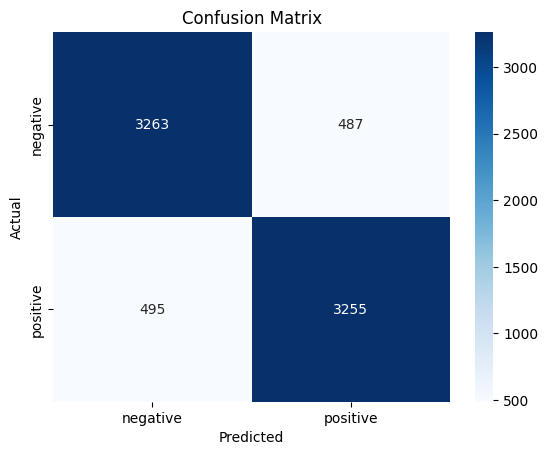

In [16]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import seaborn as sns

print("K ADHITHYA - 24BAD004")
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall:", round(recall_score(y_test, y_pred), 4))
print("F1-score:", round(f1_score(y_test, y_pred), 4))

cm = confusion_matrix(y_test, y_pred)
print(cm)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=names, yticklabels=names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()